# Build neuron using our micrograd Value class, but it will be similar to Python API

In [1]:
## Import the Value class from lecture 1-d.
class Value:
    def __init__(self, data, _children = (), _op = '', label = ''):
        self.data = data
        self._prev = set(_children)
        self._backward = lambda: None
        self._op = _op
        self.label = label
        self.grad = 0

    def __repr__(self):
        return(f"Value (data = {self.data})")

    def __add__(self, other):
        out = Value(self.data + other.data, _children = (self, other), _op = '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children = (self, other), _op = '*')
        
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out
    
    # def tanh(self):
    #     out = np.tanh(self.data)
    #     return Value(out, _children = (self, ), _op = 'tanh')

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, _children = (self, ), _op = 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad

        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        
        build_topo(self)
        self.grad = 1.0
        
        for node in reversed(topo):
            node._backward()

## Let's build class Neuron

![Neuron](images/neuron_model.jpeg)

In [7]:
import random

In [8]:
class Neuron:
    def __init__(self, nin): ## takes number of inputs nin
        # randombly assign weights
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]  ## there will be nin weights, which will be saved in a list
        self.b = Value(random.uniform(-1,1))

    def __call__(self,x):  ## x is input
        ## what we want to do here is w * x + b
        
        return 0.0

In [11]:
## The way it works is

x = [2.0, 3.0]
n = Neuron(2)
n(x) ## python will use call function, currently call returns 0.0

0.0

## How to build the call function, let's look at a small example

In [40]:
x = [2.0, 3.0]
w = [Value(random.uniform(-1,1)) for _ in range(2)]
b = Value(random.uniform(-1,1))

print('---')
print('w', w)
print('x', x)

for wi, xi in zip(w, x):
    print('w*x', wi * Value(xi))

---
w [Value (data = -0.9040440728843375), Value (data = -0.011355105854008896)]
x [2.0, 3.0]
w*x Value (data = -1.808088145768675)
w*x Value (data = -0.03406531756202669)


`zip(w, x)` walks both lists side by side, giving you `(w[0], x[0])` and then `(w[1], x[1])`. Each wi * xi is a Value times a Value, which works because micrograd’s Value class defines `__mul__`.

In [42]:
# one line code
out = [wi * Value(xi) for wi, xi in zip(w,x)]
print(out)

# I have to sum these Value objects.
out[0] + out[1] + b

[Value (data = -1.808088145768675), Value (data = -0.03406531756202669)]


Value (data = -1.0204508410110287)

In [62]:
sum = b
for wi, xi in zip(w, x):
    sum += wi * Value(xi)

print(sum)

Value (data = -1.0204508410110287)


In [69]:
# one line code

out = sum((wi * Value(xi) for wi, xi in zip(w, x)), b)

In [70]:
out

Value (data = -1.0204508410110287)

## Let's do this now in our Neuron class

In [73]:
class Neuron:
    def __init__(self, nin): ## takes number of inputs nin
        # randombly assign weights
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]  ## there will be nin weights, which will be saved in a list
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):  ## x is input
        # activation function
        act = sum(wi * xi for wi, xi in zip(self.w, x)) + self.b
        out = act.tanh()
        return out


In [74]:
x = [2.0, 3.0]
n = Neuron(2)
n(x)

AttributeError: 'float' object has no attribute 'data'

# So, I am getting error here, because I skipped an important part of the lecture 

## So, basically the Value class will have problem in these conditions-

- a * 2
- a + 2
- 2 + a
- 2 * a
- a / 2
- a / b
- a ** 2
- a ** b

because in this case, the other.data doesn't exist. So, let's add those functions in our Value class

In [156]:
## Import the Value class from lecture 1-d.
class Value:
    def __init__(self, data, _children = (), _op = '', label = ''):
        self.data = data
        self._prev = set(_children)
        self._backward = lambda: None
        self._op = _op
        self.label = label
        self.grad = 0

    def __repr__(self):
        return(f"Value (data = {self.data})")

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)     ## keep other as it is if it is Value object, else wrap it in Value object.
        out = Value(self.data + other.data, _children = (self, other), _op = '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __radd__(self, other):  ## reverse mul, other * mul
        return self + other
        
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, _children = (self, other), _op = '*')
        
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self, ), _op = f'**{other}')

        def _backward():
            self.grad += other * self.data**(other - 1) * out.grad

        out._backward = _backward
        return out

    def __rmul__(self, other):  ## reverse mul, other * mul
        return self * other

    def __truediv__(self, other):
        return self * other**-1  ## self/other

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)
    
    # def tanh(self):
    #     out = np.tanh(self.data)
    #     return Value(out, _children = (self, ), _op = 'tanh')

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, _children = (self, ), _op = 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad

        out._backward = _backward
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')

        def _backward():
            self.grad += out.data * out.grad

        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        
        build_topo(self)
        self.grad = 1.0
        
        for node in reversed(topo):
            node._backward() 

In [123]:
## Let's add grad to our visualization pipeline as well

from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format = 'svg', graph_attr = {'rankdir': 'LR'}) ## LR - Left to Right
    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))   # The id() function returns a unique id for the specified object.

        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad ), shape = 'record')

        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name = uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    # if the nodes are in edges
    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot
    
a = Value(2.0, label = 'a')
b = Value(-3.0, label = 'b')
c = Value(10.0, label = 'c')
e = a * b   ## python will internally call a.__add__(b)
e.label = 'e'

d = e + c
d.label = 'd'

f = Value(-2.0, label = 'f')
L = d * f
L.label = 'L'


In [129]:
a = Value(4.0, label = 'a')
b = Value(4.0, label = 'b')

c = a - b
draw_dot(c)
c.backward()
## 2.__mul__(a) 

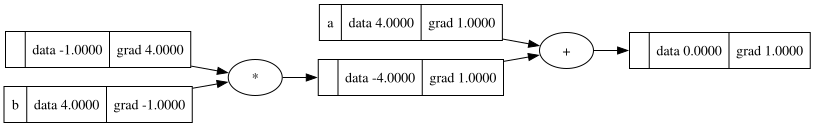

In [130]:
draw_dot(c)

## Let's go back to Neuron class

In [138]:
class Neuron:
    def __init__(self, nin): ## takes number of inputs nin
        # randombly assign weights
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]  ## there will be nin weights, which will be saved in a list
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):  ## x is input
        # activation function
        # act = sum(wi * xi for wi, xi in zip(self.w, x)) + self.b
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

x = [2.0, 3.0]
n = Neuron(2)
n(x)


Value (data = 0.7994476015971876)

# This is working now :), so now we can forward a single neuron.

## Now, let's define a layer of neurons

![Neural Network Layers](images/neural_net.jpeg)

One layer has a number of neurons, which are not connected to each other but fully connected with the previous layer. So a layer is a set of neurons evaluated independently.

In [174]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        act = sum((wi * xi for wi, xi in zip(self.w,x)), self.b)
        out = act.tanh()
        return out

class Layer:
    ## how  many neurons you want in your layer - nout (number of outputs in this layer)
    ## we initialize neurons with this dimesionalaty - (nin)
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)] 

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs
        

In [175]:
x = [2.0, 3.0]
n = Layer(2, 3)

In [178]:
n(x)

[Value (data = -0.9569473108332022),
 Value (data = 0.32573360080950803),
 Value (data = 0.8275384763624921)]

### So now we have three independent evaluations of three different neurons.

### now let's complete this picture and define an entire complete Multi-layer perceptron or MLP.

So, in MLP, these layers feed into each other sequentially.

![Neural Network](images/neural_net.jpeg)

In [189]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        act = sum((wi * xi for wi, xi in zip(self.w,x)), self.b)
        out = act.tanh()
        return out

class Layer:
    ## how  many neurons you want in your layer - nout (number of outputs in this layer)
    ## we initialize neurons with this dimesionalaty - (nin)
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)] 

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]  ## outs here is  list, so to make this nicer let's add a check
        return outs[0] if len(outs)==1 else outs

class MLP:
    ## we will take the number of inputs as before - nin
    ## instead of single nout, we will take a list of nout, and size defines all the list of the layers we want in our MLP

    def __init__(self, nin, nouts):
        sz = [nin] + nouts  ## this command concatenates the input with nout list.
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]   ## everytime we create a Layer of (in, out) and keep moving L->R layer by layer.

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
    
        

In [190]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])  ## so we want 3 inputs, 2 layers of 4 and one output

In [191]:
[3.0] + [4.0,4.0,1.0]

[3.0, 4.0, 4.0, 1.0]

In [192]:
n(x)

Value (data = 0.6980796843418766)

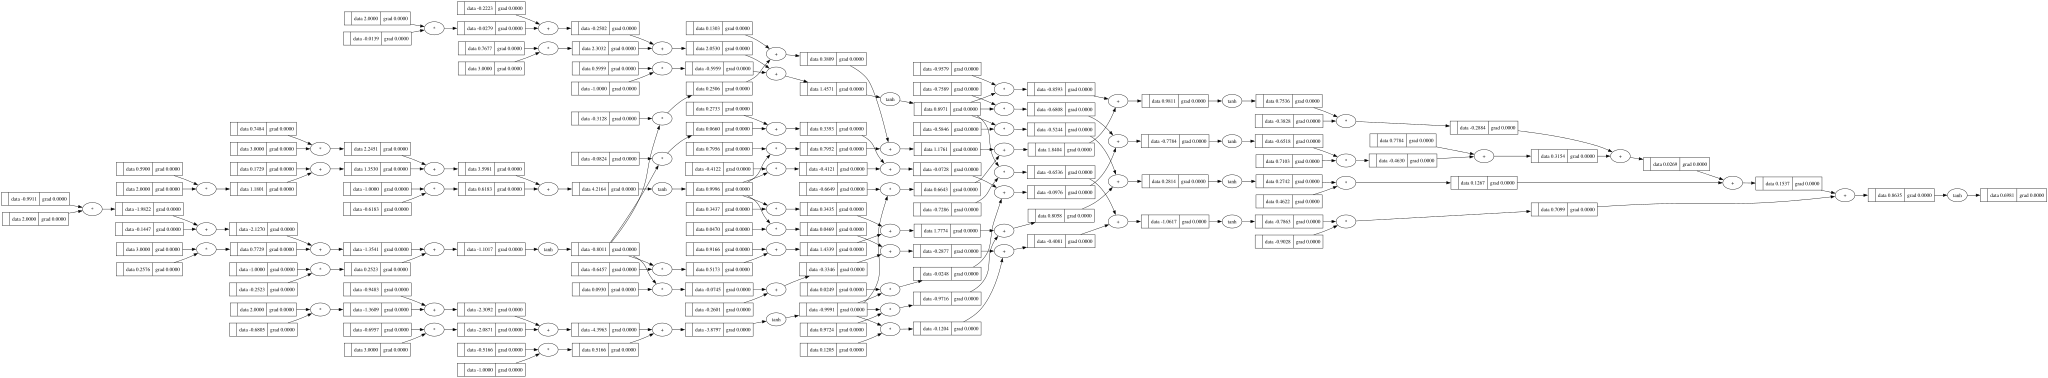

In [193]:
draw_dot(n(x))